# Posterior calibration

Coverage and rank statistics diagnose calibration over the evaluated population, but they do not guarantee calibration for every individual posterior.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'pyproject.toml').is_file())
def table(relative):
    return pd.read_csv(ROOT / 'results' / relative)
def saved_json(relative):
    return json.loads((ROOT / 'results' / relative).read_text(encoding='utf-8'))
plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 16)

Coverage is the fraction of evaluated pairs whose true mass lies in a central credible
interval. Rank-CDF distance summarizes deviation from a uniform rank reference.
β is absolute posterior-median error divided by posterior standard deviation; 0.6745
is a Gaussian median reference, not a calibration threshold.

These are held-out rank and coverage checks inspired by SBC, rather than a formal
prior-predictive SBC experiment. The early block-grid summaries use 200 draws; the
final-six and follow-up comparisons use 500 draws. Discrete ranks must be interpreted
with their finite number of possible values.


,model,domain,n,coverage68,coverage95,median_beta,rank_cdf_distance,mean_width68,mean_width95
0,combined_dynamics,flamingo,21409,0.747256,0.957588,0.588495,0.158116,0.552660,1.072629
1,combined_dynamics,tng,231,0.731602,0.917749,0.561410,0.114913,0.544626,1.053369
4,combined_stellar_sum,flamingo,21409,0.712831,0.949787,0.617495,0.216520,0.358127,0.700890
5,combined_stellar_sum,tng,231,0.640693,0.900433,0.707035,0.266895,0.369217,0.719339
8,flamingo_dynamics,flamingo,21409,0.728385,0.940539,0.598435,0.034925,0.440306,0.860607
9,flamingo_dynamics,tng,231,0.649351,0.852814,0.636580,0.202789,0.470468,0.914919
12,flamingo_stellar_sum,flamingo,21409,0.696343,0.947125,0.645678,0.015164,0.253892,0.497226
13,flamingo_stellar_sum,tng,231,0.199134,0.497835,1.923209,0.653550,0.305918,0.596350
16,tng_dynamics,flamingo,21409,0.604559,0.940212,0.811816,0.278803,0.591632,1.153143
17,tng_dynamics,tng,231,0.718615,0.939394,0.615027,0.085854,0.559206,1.086564


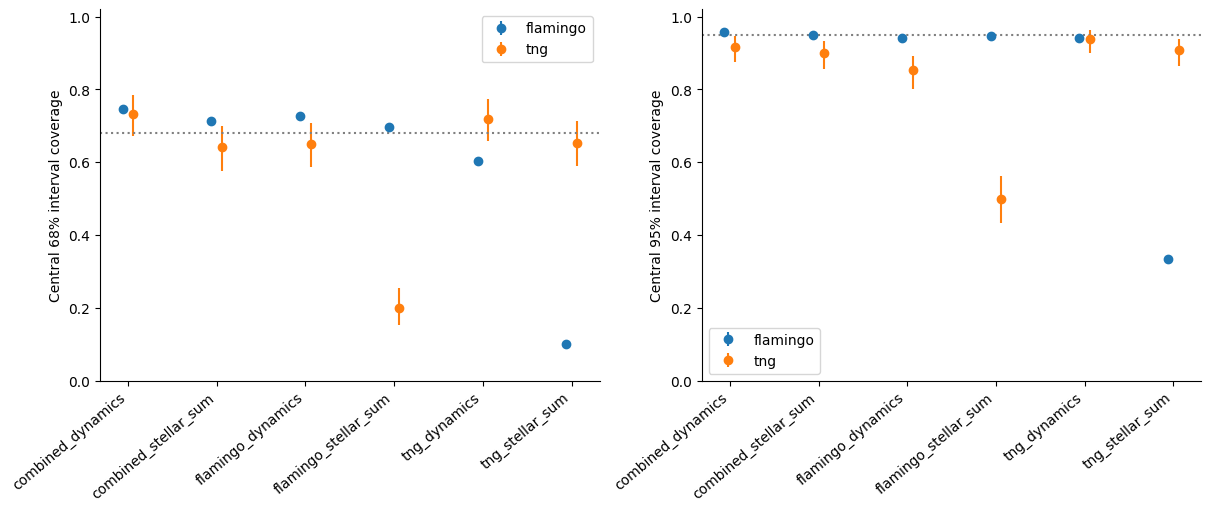

In [2]:
calibration=table('calibration/final_calibration_with_binomial_intervals.csv')
display(calibration.query("subset == 'pooled'")[
    ['model','domain','n','coverage68','coverage95','median_beta','rank_cdf_distance','mean_width68','mean_width95']])
fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
use=calibration.query("subset == 'pooled'").copy()
for ax,level in zip(axes,[68,95]):
    c=f'coverage{level}'
    for j,(domain,part) in enumerate(use.groupby('domain')):
        x=np.arange(len(part)) + (j-.5)*.12
        ax.errorbar(x,part[c],yerr=np.vstack([part[c]-part[c+'_wilson95_lower'],
            part[c+'_wilson95_upper']-part[c]]),fmt='o',label=domain)
    ax.axhline(level/100,color='gray',ls=':');ax.set_ylim(0,1.02)
    ax.set_xticks(np.arange(len(part)),part.model,rotation=40,ha='right')
    ax.set_ylabel(f'Central {level}% interval coverage');ax.legend()
plt.show()

,block,training,evaluation,n,draws,coverage68,coverage95,rank_cdf_distance,median_beta,coverage68_wilson95_lower,coverage68_wilson95_upper,coverage95_wilson95_lower,coverage95_wilson95_upper
0,core_dynamics,flamingo,flamingo,21409,200,0.685786,0.944463,0.011100,0.661942,0.679535,0.691971,0.941314,0.947451
1,core_chemistry,flamingo,flamingo,21409,200,0.684478,0.943015,0.015659,0.661624,0.678221,0.690670,0.939829,0.946041
2,core_morphology,flamingo,flamingo,21409,200,0.686253,0.936429,0.014636,0.661063,0.680005,0.692435,0.933081,0.939619
3,core_photometry,flamingo,flamingo,21409,200,0.693820,0.943435,0.019810,0.654344,0.687612,0.699959,0.940260,0.946451
4,all_features,flamingo,flamingo,21409,200,0.698818,0.940632,0.023390,0.637502,0.692638,0.704927,0.937387,0.943720
5,core_dynamics,flamingo,tng,231,200,0.627706,0.865801,0.292111,0.694858,0.563754,0.687479,0.815813,0.903822
6,core_chemistry,flamingo,tng,231,200,0.610390,0.852814,0.281515,0.723848,0.546187,0.670981,0.801364,0.892722
7,core_morphology,flamingo,tng,231,200,0.151515,0.424242,0.705111,2.160597,0.111005,0.203426,0.362259,0.488704
8,core_photometry,flamingo,tng,231,200,0.597403,0.848485,0.322802,0.784778,0.533066,0.658553,0.796574,0.888995
9,all_features,flamingo,tng,231,200,0.151515,0.389610,0.709375,2.333003,0.111005,0.203426,0.329019,0.453813


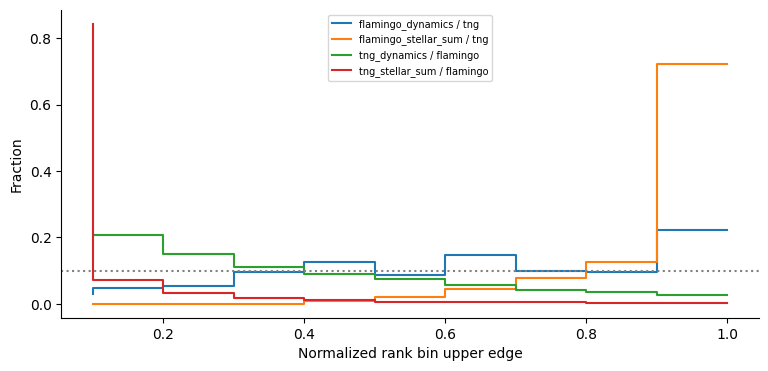

In [3]:
display(table('calibration/block_calibration_same_evaluation_as_section_5_3.csv'))
ranks=table('calibration/rank_histogram_bins.csv')
fig,ax=plt.subplots()
for (model,evaluation),part in ranks.groupby(['model','evaluation']):
    ax.step(part.upper_normalized_rank,part.fraction,where='pre',label=model+' / '+evaluation)
ax.axhline(.1,color='gray',ls=':');ax.set(xlabel='Normalized rank bin upper edge',ylabel='Fraction')
ax.legend(fontsize=7);plt.show()

The Wilson bars summarize finite-count binomial uncertainty; they do not incorporate
shared-host dependence, fitting uncertainty or cosmic variance. Connected-component
paired intervals from notebook 04 answer a different question. Large R² and narrow
posteriors do not establish reliable uncertainties under simulation transfer.

Original [within-simulation rank notebook](../research/notebooks/original/SBC.ipynb),
[cross-simulation rank notebook](../research/notebooks/original/SBC_Cross-Simulation.ipynb),
and [metric implementation](../research/src/lg_npe/evaluation.py).


[Previous](04_within_and_cross_simulation.ipynb) · [Next](06_bootstrap_and_sample_size.ipynb) · [Repository map](../README.md)
